<a href="https://colab.research.google.com/github/Berenice-Olawale/Brainwave_Matrix_Intern/blob/main/image_classifier_robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# EPFL Summer Internship Research Project
# Step 1: Check our Python environment

import sys

print("Python version:", sys.version)

# Check our main scientific libraries
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision

print("NumPy version:", np.__version__)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("GPU available:", torch.cuda.is_available())
print("Environment setup successful!")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy version: 2.1.3
PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu
GPU available: False
Environment setup successful!


In [2]:
import torch
import torchvision
from torchvision.models import resnet18, ResNet18_Weights

# Choose the device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load pretrained model weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Switch to evaluation mode
model = model.to(device)
model.eval()

# Get the correct image preprocessing steps
preprocess = weights.transforms()

# Load ImageNet category names
categories = weights.meta["categories"]

print("Model:", "ResNet-18")
print("Device:", device)
print("Number of categories:", len(categories))
print("Model loaded successfully!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 110MB/s]


Model: ResNet-18
Device: cpu
Number of categories: 1000
Model loaded successfully!


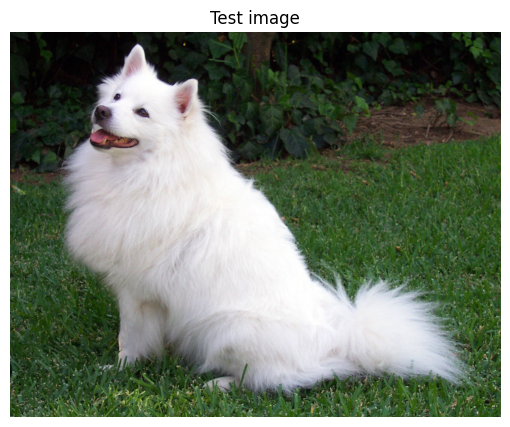

Samoyed: 88.46%
Arctic fox: 4.58%
white wolf: 4.43%


In [3]:
from PIL import Image
import matplotlib.pyplot as plt
import urllib.request
from io import BytesIO

image_url = (
    "https://raw.githubusercontent.com/"
    "pytorch/hub/master/images/dog.jpg"
)

with urllib.request.urlopen(image_url) as response:
    image = Image.open(BytesIO(response.read())).convert("RGB")

# Prepare the image for ResNet-18
input_tensor = preprocess(image).unsqueeze(0).to(device)

# Get predictions without calculating gradients
with torch.inference_mode():
    output = model(input_tensor)
    probabilities = torch.softmax(output[0], dim=0)

# Display the three most likely categories
top_probabilities, top_indices = torch.topk(probabilities, 3)

plt.figure(figsize=(7, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Test image")
plt.show()

for probability, index in zip(
    top_probabilities.cpu(), top_indices.cpu()
):
    print(
        f"{categories[index.item()]}: "
        f"{probability.item() * 100:.2f}%"
    )

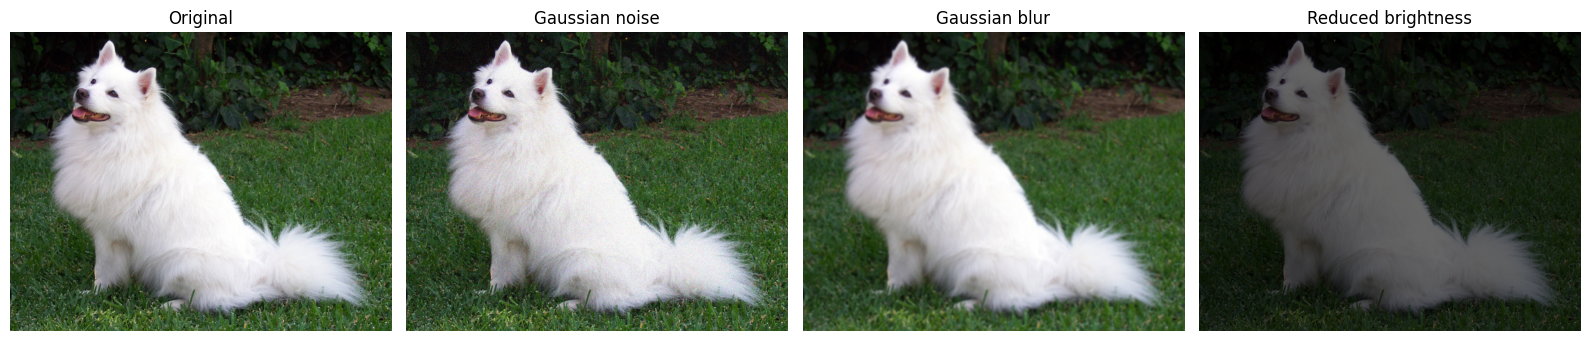

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageFilter

# 1. Keep the original image as our baseline
original = image.convert("RGB")

# 2. Add Gaussian noise
np.random.seed(42)  # Makes the experiment reproducible
image_array = np.asarray(original).astype(np.float32)

noise = np.random.normal(
    loc=0,
    scale=25,
    size=image_array.shape
)

noisy_array = np.clip(
    image_array + noise,
    0,
    255
).astype(np.uint8)

noisy_image = Image.fromarray(noisy_array)

# 3. Apply Gaussian blur
blurred_image = original.filter(
    ImageFilter.GaussianBlur(radius=3)
)

# 4. Reduce brightness to 40% of the original
dark_image = ImageEnhance.Brightness(
    original
).enhance(0.4)

# Collect the images for comparison
images = {
    "Original": original,
    "Gaussian noise": noisy_image,
    "Gaussian blur": blurred_image,
    "Reduced brightness": dark_image
}

# Display all four images
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [5]:

for name, img in images.items():
    # Apply the model's required preprocessing
    input_tensor = preprocess(img).unsqueeze(0).to(device)

    # Run inference without calculating gradients
    with torch.inference_mode():
        output = model(input_tensor)
        probabilities = torch.softmax(output[0], dim=0)

    # Find the three most likely categories
    top_probabilities, top_indices = torch.topk(
        probabilities, 3
    )

    print(f"\n{name}")
    print("-" * 35)

    for probability, index in zip(
        top_probabilities.cpu(),
        top_indices.cpu()
    ):
        category = categories[index.item()]
        confidence = probability.item() * 100

        print(f"{category}: {confidence:.2f}%")



Original
-----------------------------------
Samoyed: 88.46%
Arctic fox: 4.58%
white wolf: 4.43%

Gaussian noise
-----------------------------------
Samoyed: 90.75%
white wolf: 3.78%
Arctic fox: 2.92%

Gaussian blur
-----------------------------------
Samoyed: 74.05%
Arctic fox: 10.31%
white wolf: 7.17%

Reduced brightness
-----------------------------------
Samoyed: 92.79%
Arctic fox: 1.96%
white wolf: 1.44%


In [6]:

import pandas as pd
import numpy as np
from PIL import ImageEnhance, ImageFilter

# The original image's top prediction
original_tensor = preprocess(original).unsqueeze(0).to(device)

with torch.inference_mode():
    original_output = model(original_tensor)
    original_probs = torch.softmax(original_output[0], dim=0)

original_class_index = original_probs.argmax().item()
original_class = categories[original_class_index]

print("Original predicted class:", original_class)

# Create images at different distortion strengths
experiments = [("Original", 0, original)]

# Noise: increasing standard deviation
base_array = np.asarray(original).astype(np.float32)

for sigma in [10, 25, 50]:
    rng = np.random.default_rng(42)
    noise = rng.normal(0, sigma, base_array.shape)
    noisy = np.clip(base_array + noise, 0, 255).astype(np.uint8)
    experiments.append(
        (f"Noise sigma={sigma}", sigma, Image.fromarray(noisy))
    )

# Blur: increasing radius
for radius in [1, 3, 6]:
    blurred = original.filter(
        ImageFilter.GaussianBlur(radius=radius)
    )
    experiments.append(
        (f"Blur radius={radius}", radius, blurred)
    )

# Brightness: progressively darker
for factor in [0.8, 0.5, 0.2]:
    darkened = ImageEnhance.Brightness(original).enhance(factor)
    experiments.append(
        (f"Brightness={factor}", factor, darkened)
    )

# Evaluate each image
results = []

for condition, strength, img in experiments:
    tensor = preprocess(img).unsqueeze(0).to(device)

    with torch.inference_mode():
        output = model(tensor)
        probs = torch.softmax(output[0], dim=0)

    predicted_index = probs.argmax().item()

    results.append({
        "Condition": condition,
        "Strength": strength,
        "Predicted class": categories[predicted_index],
        "Original-class confidence (%)":
            probs[original_class_index].item() * 100,
        "Top prediction confidence (%)":
            probs[predicted_index].item() * 100
    })

results_df = pd.DataFrame(results)
display(results_df.round(2))


Original predicted class: Samoyed


,Condition,Strength,Predicted class,Original-class confidence (%),Top prediction confidence (%)
0,Original,0.0,Samoyed,88.46,88.46
1,Noise sigma=10,10.0,Samoyed,89.18,89.18
2,Noise sigma=25,25.0,Samoyed,90.42,90.42
3,Noise sigma=50,50.0,Samoyed,92.67,92.67
4,Blur radius=1,1.0,Samoyed,87.48,87.48
5,Blur radius=3,3.0,Samoyed,74.05,74.05
6,Blur radius=6,6.0,Samoyed,51.47,51.47
7,Brightness=0.8,0.8,Samoyed,92.98,92.98
8,Brightness=0.5,0.5,Samoyed,94.32,94.32
9,Brightness=0.2,0.2,Samoyed,79.71,79.71


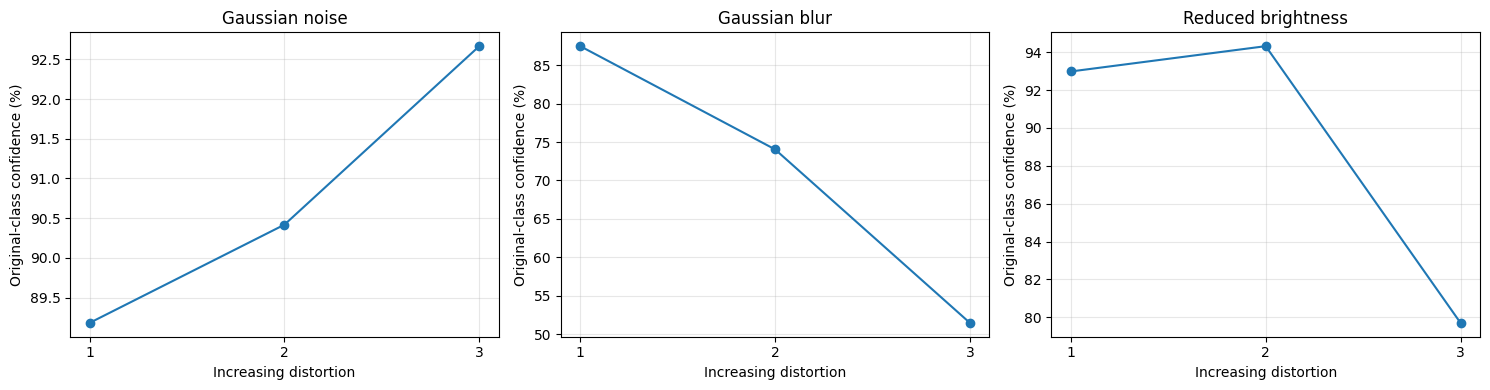

In [7]:

import matplotlib.pyplot as plt

groups = {
    "Gaussian noise": [
        ("Noise sigma=10", 10),
        ("Noise sigma=25", 25),
        ("Noise sigma=50", 50)
    ],
    "Gaussian blur": [
        ("Blur radius=1", 1),
        ("Blur radius=3", 3),
        ("Blur radius=6", 6)
    ],
    "Reduced brightness": [
        ("Brightness=0.8", 0.8),
        ("Brightness=0.5", 0.5),
        ("Brightness=0.2", 0.2)
    ]
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (group_name, settings) in zip(axes, groups.items()):
    subset = results_df[
        results_df["Condition"].isin(
            [condition for condition, _ in settings]
        )
    ].copy()

    subset["Order"] = subset["Condition"].apply(
        lambda name: [
            condition for condition, _ in settings
        ].index(name)
    )
    subset = subset.sort_values("Order")

    ax.plot(
        range(1, len(subset) + 1),
        subset["Original-class confidence (%)"],
        marker="o"
    )
    ax.set_title(group_name)
    ax.set_xlabel("Increasing distortion")
    ax.set_ylabel("Original-class confidence (%)")
    ax.set_xticks([1, 2, 3])
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [1]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("We are currently using the CPU.")


PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:

import torch
import torchvision
from torchvision.datasets import CIFAR10
from torchvision import transforms

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Convert CIFAR-10 images into PyTorch tensors
transform = transforms.ToTensor()

# Download the training and test sets
train_dataset = CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

class_names = train_dataset.classes

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", class_names)


PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


 22%|██▏       | 38.1M/170M [08:52<29:58, 73.6kB/s]